In [12]:
import os
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from darkmod.crystal import Crystal
from darkmod import laue

%matplotlib inline


In [2]:
dislocation_density = np.load("/dtu/3d-imaging-center/projects/2022_QIM_PMP/analysis/Adam/CDD/Microstructures/dislocation_density_1560.npy")


In [3]:
unit_cell = [3.52, 3.52, 3.52, 90.0, 90.0, 90.0]
H = np.array([[1, -1, 0], [1, 1, 0], [0, 0, 1]]).T
orientation = H / np.linalg.norm(H, axis=0)
hkl = np.array([2, -2, 0])
energy = 19.2  # keV

unit_scale = 1e12


In [4]:
crystal = Crystal(unit_cell, orientation)
d = np.pi * 2 / np.linalg.norm(crystal.U @ crystal.B @ hkl)
theta = np.arcsin(laue.keV_to_angstrom(energy) / (2 * d))
crystal.align(hkl, axis=np.array([0, 0, 1]))
crystal.align(np.array([1, 1, 0]), axis=np.array([1, 0, 0]), transformation_hkl=hkl)
phi_0 = -theta
crystal.goniometer.relative_move(dphi=0, dchi=0, domega=0, dmu=phi_0)

In [5]:
R = crystal.goniometer.R  # maps crystal -> lab
M = R.T  # output(lab) -> input(crystal) for affine_transform


In [6]:
nx, ny, nz = dislocation_density.shape[:3]
center = (np.array([nx, ny, nz]) - 1) / 2.0
offset = center - M @ center

rho_rot = ndi.affine_transform(
    dislocation_density,
    M,
    offset=offset,
    order=1,
    mode="nearest",
)

cz = int(center[2])
rho_slice = rho_rot[:, :, cz]

rho_slice_si = rho_slice * unit_scale


In [19]:
aspect = 1/np.cos(theta)
print(aspect)

1.0354548584567067


In [22]:
max = np.max(rho_slice_si)
min = np.min(rho_slice_si)
print(max, min)


154458499288966.0 138410959772.00287


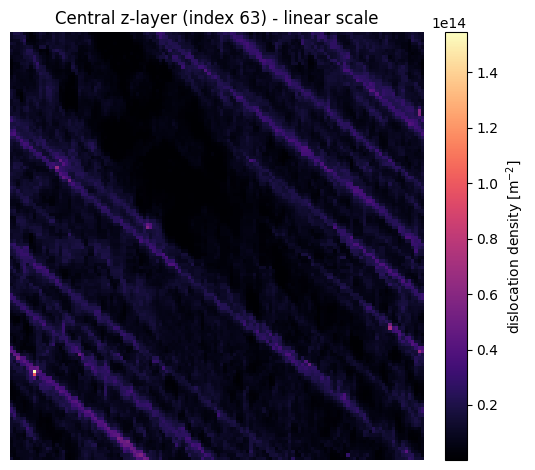

In [26]:
plt.figure()
im = plt.imshow(rho_slice_si, origin="lower", aspect=aspect, cmap="magma")
plt.colorbar(im, fraction=0.046, pad=0.04, label="dislocation density [m$^{-2}$]")
plt.title(f"Central z-layer (index {cz}) - linear scale")
plt.axis("off")
plt.tight_layout()
plt.show()

In [10]:
# Log scale image (avoid log(0) by adding small epsilon)
positive = rho_slice_si[rho_slice_si > 0]
eps = 1e-20 if positive.size == 0 else max(1e-20, np.percentile(positive, 0.1))
rho_log = np.log10(np.maximum(rho_slice_si, eps))

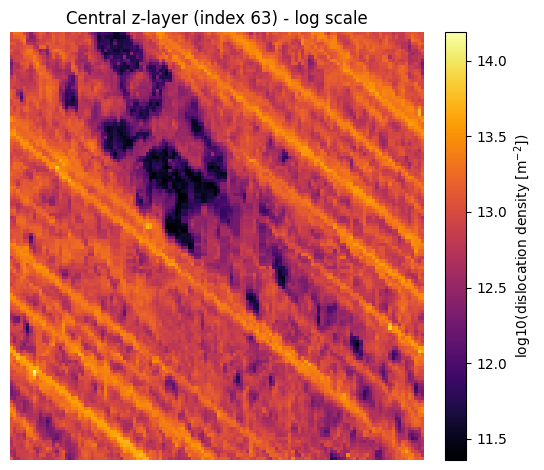

In [30]:
plt.figure()
im = plt.imshow(rho_log, origin="lower", aspect=aspect, cmap="inferno")
plt.colorbar(im, fraction=0.046, pad=0.04, label="log10(dislocation density [m$^{-2}$])")
plt.title(f"Central z-layer (index {cz}) - log scale")
plt.axis("off")
plt.tight_layout()
plt.show()